In [1]:
import numpy as np
import matplotlib.pyplot as plt
from ipywidgets import interactive

dt = 0.001
dx = 0.05

# Write code to give an array of times starting at t=0 and ending 
# at t=1.  Be sure that you use many points in the partition of 
# the time domain.  Be sure to either specify or calculate the 
# value of Delta t.
t = np.linspace(0,1,int(1+1/dt))

# Write code to give an array of x values starting at x=0 and 
# ending exactly at x=1. This is best done with the np.linspace() 
# command since you can guarantee that you end exactly at x=1.  
# Be sure to either specify or calculate the value of Delta x as
# part of your code. 
x = np.linspace(0,1,int(1+1/dx))

# The next two lines build two parameters that are of interest 
# for the finite difference scheme.
c = 1 # The wavespeed
# The coefficient "a" appears in the finite difference scheme.
a = c*dt**2 / dx**2
print("dt=",dt,", dx=",dx," and c dt^2/dx^2=",a)



U = np.zeros( (len(t),len(x)) )
U[:,0] = 0.4*np.sin(np.pi*t) # left boundary condition
U[:,-1] = 0 # right boundary condition
U[0,:] = 0 # the function for the init. condition (should depend on x)
U[1,:] = U[0,:]

for n in range(1,len(t)-1):
    U[n+1,1:-1] = 2*U[n,1:-1]-U[n-1,1:-1] + a*( U[n,:-2] - 2*U[n,1:-1] + U[n,2:])
    
    
def plotter(Frame):
    plt.plot(x,U[Frame,:],'b')
    plt.grid()
    plt.ylim(-1,1)
    plt.show()
interactive_plot = interactive(plotter, Frame=(0,len(t)-1,1))
interactive_plot

dt= 0.001 , dx= 0.05  and c dt^2/dx^2= 0.0003999999999999999


interactive(children=(IntSlider(value=500, description='Frame', max=1000), Output()), _dom_classes=('widget-in…

In [2]:
from ipywidgets import interactive

dt = 0.001
dx = 0.05

# Write code to give an array of times starting at t=0 and ending 
# at t=1.  Be sure that you use many points in the partition of 
# the time domain.  Be sure to either specify or calculate the 
# value of Delta t.
t = np.linspace(0,1,int(1+1/dt))

# Write code to give an array of x values starting at x=0 and 
# ending exactly at x=1. This is best done with the np.linspace() 
# command since you can guarantee that you end exactly at x=1.  
# Be sure to either specify or calculate the value of Delta x as
# part of your code. 
x = np.linspace(0,1,int(1+1/dx))

# The next two lines build two parameters that are of interest 
# for the finite difference scheme.
c = 1 # The wavespeed
# The coefficient "a" appears in the finite difference scheme.
a = c*dt**2 / dx**2
print("dt=",dt,", dx=",dx," and c dt^2/dx^2=",a)



U = np.zeros( (len(t),len(x)) )
U[:,0] = 0 # left boundary condition
U[:,-1] = 0 # right boundary condition
U[0,:] = 4*x*(1-x) # the function for the init. condition (should depend on x)
U[1,:] = U[0,:]

for n in range(1,len(t)-1):
    U[n+1,1:-1] = 2*U[n,1:-1]-U[n-1,1:-1] + a*( U[n,:-2] - 2*U[n,1:-1] + U[n,2:])
    
    
def plotter(Frame):
    plt.plot(x,U[Frame,:],'b')
    plt.grid()
    plt.ylim(-1,1)
    plt.show()
interactive_plot = interactive(plotter, Frame=(0,len(t)-1,1))
interactive_plot

dt= 0.001 , dx= 0.05  and c dt^2/dx^2= 0.0003999999999999999


interactive(children=(IntSlider(value=500, description='Frame', max=1000), Output()), _dom_classes=('widget-in…

# 6.46

## a.
$u_{tt}(t_n, x_i) \approx \frac{U_i^{n+1} - 2U_i^n + U_i^{n-1}}{\Delta t^2}$

## b.
$u_{xx}(t_n, x_i) \approx \frac{U_{i+1}^n - 2U_i^n + U_{i-1}^n}{\Delta x^2}$

## c.
$\frac{U_i^{n+1} - 2U_i^n + U_i^{n-1}}{\Delta t^2} = c \frac{U_{i+1}^n - 2U_i^n + U_{i-1}^n}{\Delta x^2}$

## d.
$ U_i^{n+1} = 2U_i^n - U_i^{n-1} + \frac{c\Delta t^2}{\Delta x^2}(U_{i+1}^n - 2U_i^n + U_{i-1}^n)$

## e.
We need bothe initial displacement and velocity.

## f.
For the wave equation with the initial and boundary conditions provided, we discretize the domain, apply the initial conditions, and iteratively compute the solution at each subsequent time step.

# 6.51 
The setup probably appears in a lab where ask a mechanical oscillation, which simplifies a model of earthquake waves.<br>
We can change the boundary condition to a different function, and then trace the changing oscillation.

# 6.58

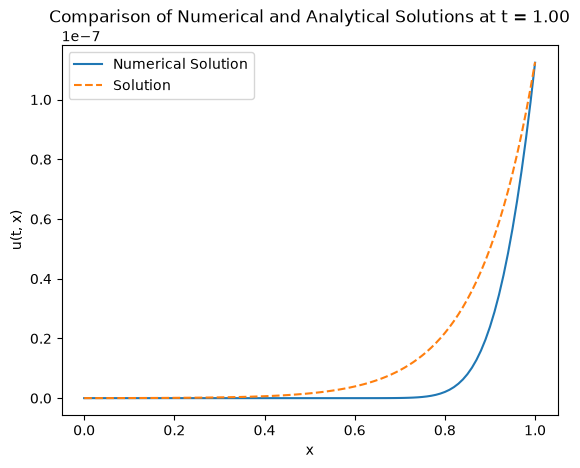

In [3]:

v = 1.0  # wave speed
x_start, x_end = 0, 1
dx = 0.01
t_start, t_end = 0, 1
dt = 0.001

x = np.linspace(x_start, x_end, int(1/dx + 1))
t = np.linspace(t_start, t_end, int(1/dt + 1))

# solution matrix
U = np.zeros((len(t), len(x)))

#initial conditions
U[0, :] = np.exp(-(x - 4)**2)

# Compute solution for each time step
for n in range(len(t) - 1):
    U[n + 1, 1:] = U[n, 1:] - v * dt / dx * (U[n, 1:] - U[n, :-1])

# Analytical solution for comparison
U_analytical = np.exp(-(x - 4 - v * t_end)**2)

# Plot numerical and analytical solutions at final time
plt.plot(x, U[-1, :], label='Numerical Solution')
plt.plot(x, U_analytical, label='Solution', linestyle='--')
plt.title('Comparison of Numerical and Analytical Solutions at t = {:.2f}'.format(t_end))
plt.xlabel('x')
plt.ylabel('u(t, x)')
plt.legend()
plt.show()


In [4]:
from ipywidgets import interactive

v = 1.0  # wave speed
x_start, x_end = 0, 1
dx = 0.01
t_start, t_end = 0, 1
dt = 0.001

x = np.linspace(x_start, x_end, int(1/dx + 1))
t = np.linspace(t_start, t_end, int(1/dt + 1))

# solution matrix
U = np.zeros((len(t), len(x)))

#initial conditions
U[0, :] = np.exp(-(x - 4)**2)

# Compute solution for each time step
for n in range(len(t) - 1):
    U[n + 1, 1:] = U[n, 1:] - v * dt / dx * (U[n, 1:] - U[n, :-1])


def plotter(Frame):
    plt.plot(x,U[Frame,:],'b')
    plt.grid()
    plt.ylim(-1,1)
    plt.show()
interactive_plot = interactive(plotter, Frame=(0,len(t)-1,1))
interactive_plot

interactive(children=(IntSlider(value=500, description='Frame', max=1000), Output()), _dom_classes=('widget-in…